# Hệ Thống Nhận Diện và Phân Loại Biển Báo Giao Thông Việt Nam (Two-Stage Pipeline)
### Notebook Walkthrough: Trực quan hóa kiến trúc, thực nghiệm và kết quả

Notebook này hướng dẫn qua từng thành phần của hệ thống nhận diện biển báo giao thông 2 giai đoạn:
1. **Thiết lập & Khám phá cấu trúc:** Kiểm tra tài nguyên và đường dẫn.
2. **Kiến trúc Pipeline:** Sơ đồ tổng thể ghép nối Detector và Classifier.
3. **Chiến lược chia dữ liệu (Data Split):** Giải quyết triệt để rò rỉ dữ liệu (Block Split).
4. **Bộ phát hiện (Detector - YOLO11s):** Đánh giá mAP, Recall theo kích thước và trực quan hóa ảnh hiện trường.
5. **Kỹ thuật trích xuất đặc trưng (S0 -> S3):** Phân tích màu HSV, không gian lưới và kết cấu HOG.
6. **Bộ phân loại 5 nhóm (Classifier):** So sánh SVM (RBF kernel), RF, XGBoost, LightGBM và Confusion Matrix.
7. **Phân tích định tính (Qualitative Analysis):** Contact sheets các mẫu True Positives, Phân loại sai, Bỏ sót và Báo động giả.
8. **Đánh giá End-to-End toàn hệ thống:** So sánh 3 mức Level A, Level A', Level B.
9. **Inference Template:** Code mẫu nạp weights dự đoán trên ảnh mới.


In [1]:
from pathlib import Path
import json
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display, Image
except ImportError:
    def display(*args):
        for a in args:
            print(a)
    class Image:
        def __init__(self, filename=None, width=None):
            self.filename = filename
            self.width = width
        def _repr_png_(self):
            return open(self.filename, 'rb').read()

ROOT_DIR = Path("..")
ASSETS_DIR = ROOT_DIR / "assets"
RESULTS_DIR = ROOT_DIR / "results"
DOCS_DIR = ROOT_DIR / "docs"

print("✓ Đã nạp thành công các thư viện cơ bản.")
print(f"✓ Thư mục assets tồn tại: {ASSETS_DIR.exists()}")
print(f"✓ Thư mục results tồn tại: {RESULTS_DIR.exists()}")


✓ Đã nạp thành công các thư viện cơ bản.
✓ Thư mục assets tồn tại: True
✓ Thư mục results tồn tại: True


## 1. Kiến Trúc Hệ Thống (Pipeline Overview)

Hệ thống hoạt động theo quy trình 2 giai đoạn:
- **Stage 1 (Detector):** YOLO11s nhận diện vùng biên (bbox) của mọi biển báo trên ảnh đường phố thực tế (Single-class detector).
- **Stage 2 (Classifier):** Cắt (crop) vùng ảnh biển báo, tiền xử lý và trích xuất vector đặc trưng đa tầng (HSV + Lưới không gian + Hình học + HOG), sau đó đưa qua bộ phân loại **SVM (RBF kernel)** để phân nhóm theo quy chuẩn QCVN 41:2019 (Cấm, Cảnh báo, Hiệu lệnh, Chỉ dẫn, Phụ).


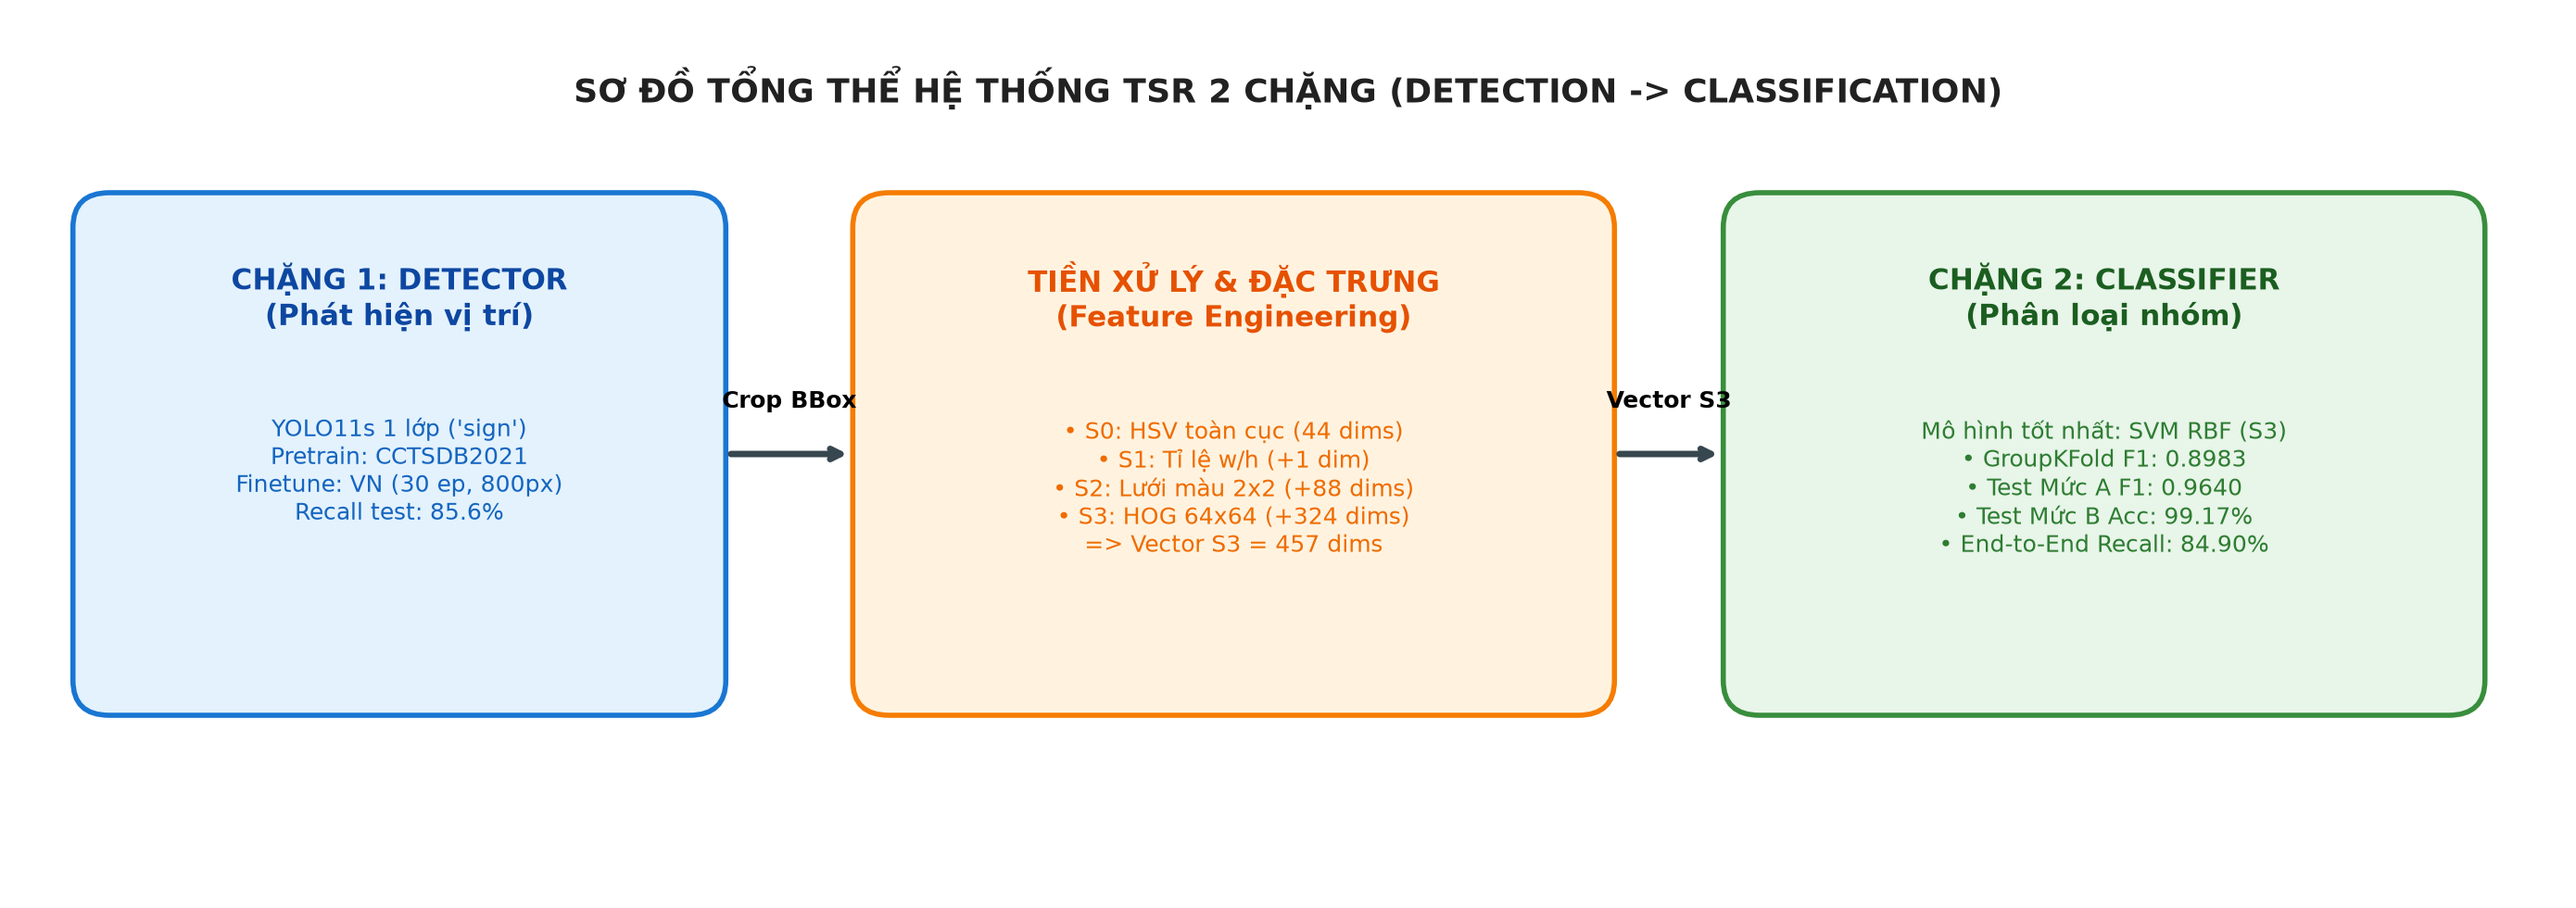

In [2]:
display(Image(filename=str(ASSETS_DIR / "diagrams" / "pipeline_overview.png"), width=800))


## 2. Chiến Lược Phân Chia Dữ Liệu (Block Split vs Random Split)

Trong dữ liệu camera hành trình (dashcam video), các khung hình liền kề (stems liên tiếp) chứa cùng một biển báo vật lý ở các khoảng cách khác nhau.
- Nếu **chia ngẫu nhiên theo ảnh (Random Split)**, các frame liên tiếp sẽ bị phân tán vào cả train và test, dẫn đến **rò rỉ dữ liệu lên tới 46.84%** số biển test.
- Hệ thống áp dụng **Block Split (chia theo khối video liên tục)**: toàn bộ một đoạn đường / chuỗi frame chỉ thuộc về Train, Val hoặc Test, đảm bảo **Rò rỉ dữ liệu = 0%**.
- Ngoài ra, kiểm định chéo **GroupKFold 5-fold** được thực hiện trên **toàn bộ 18.496 mẫu** (chia theo cụm block video liên tục) để lựa chọn cấu hình siêu tham số tối ưu.


In [3]:
split_data = {
    "Split": ["Train", "Val", "Test", "Tổng cộng (GroupKFold)"],
    "Số ảnh": [2072, 172, 550, 2794],
    "Cấm (P)": [10135, 352, 1096, 11583],
    "Cảnh báo (W)": [3252, 126, 423, 3801],
    "Hiệu lệnh (R)": [1341, 60, 219, 1620],
    "Chỉ dẫn (I)": [954, 4, 75, 1033],
    "Phụ (S)": [435, 16, 8, 459],
    "Tổng số biển (đã bỏ Camera)": [16117, 558, 1821, 18496]
}
df_split = pd.DataFrame(split_data)
display(df_split)
print("✓ Block Split đảm bảo 0% biển test bị trùng chuỗi khung hình với train.")


Split  Số ảnh  Cấm (P)  Cảnh báo (W)  Hiệu lệnh (R)  Chỉ dẫn (I)  Phụ (S)  Tổng số biển (đã bỏ Camera)
0                    Train    2072    10135          3252           1341          954      435                        16117
1                      Val     172      352           126             60            4       16                          558
2                     Test     550     1096           423            219           75        8                         1821
3  Tổng cộng (GroupKFold)    2794    11583          3801           1620         1033      459                        18496
✓ Block Split đảm bảo 0% biển test bị trùng chuỗi khung hình với train.


## 3. Hiệu Năng Bộ Phát Hiện (Detector - YOLO11s)

Mô hình YOLO11s được fine-tune 30 epochs từ weights pretrain CCTSDB trên bộ dữ liệu Việt Nam.
- **mAP50:** **83.60%** | **mAP50-95:** **60.10%** (trên tập Test 550 ảnh).
- **Recall tổng thể (conf=0.25, IoU>=0.5):** **85.61%** (1.559 / 1.821 biển GT, đã loại trừ Camera). Tỷ lệ bỏ sót: **14.39%** (262 / 1.821).
- **Chi tiết bắt trúng theo nhóm:**
  - Cảnh báo: **96.45%** (408 / 423)
  - Chỉ dẫn: **90.67%** (68 / 75)
  - Cấm: **84.31%** (924 / 1.096)
  - Hiệu lệnh: **72.60%** (159 / 219)
  - Phụ: **0.00%** (0 / 8 - toàn bộ 8 biển phụ ở xa/nhỏ đều bị bỏ sót hoàn toàn)


In [4]:
det_summary = {
    "Nhóm": ["Cấm (P)", "Cảnh báo (W)", "Hiệu lệnh (R)", "Chỉ dẫn (I)", "Phụ (S)", "Tổng 5 nhóm (bỏ Camera)"],
    "Tổng GT": [1096, 423, 219, 75, 8, 1821],
    "Ghép trúng (TP)": [924, 408, 159, 68, 0, 1559],
    "Bỏ sót (FN)": [172, 15, 60, 7, 8, 262],
    "Recall (%)": [84.31, 96.45, 72.60, 90.67, 0.00, 85.61]
}
df_det = pd.DataFrame(det_summary)
display(df_det)


Nhóm  Tổng GT  Ghép trúng (TP)  Bỏ sót (FN)  Recall (%)
0                  Cấm (P)     1096              924          172       84.31
1             Cảnh báo (W)      423              408           15       96.45
2            Hiệu lệnh (R)      219              159           60       72.60
3              Chỉ dẫn (I)       75               68            7       90.67
4                  Phụ (S)        8                0            8        0.00
5  Tổng 5 nhóm (bỏ Camera)     1821             1559          262       85.61


## 4. Chuỗi Đặc Trưng Thị Giác (Feature Evolution S0 -> S3)

Hệ thống nâng cấp đặc trưng qua 4 nấc:
- **S0 (Màu toàn cục - 44 chiều):** Histogram HSV (H36 + S8).
- **S1 (+ Hình học - 45 chiều):** Thêm tỷ lệ khung hình w/h.
- **S2 (+ Lưới không gian - 133 chiều):** Bổ sung histogram HSV trên lưới $2 \times 2$ nhận biết bố cục và viền màu.
- **S3 (+ Kết cấu HOG - 457 chiều):** Bổ sung 324 chiều Histogram of Oriented Gradients (HOG) phân giải viền tròn/tam giác/chữ nhật và ký hiệu bên trong.


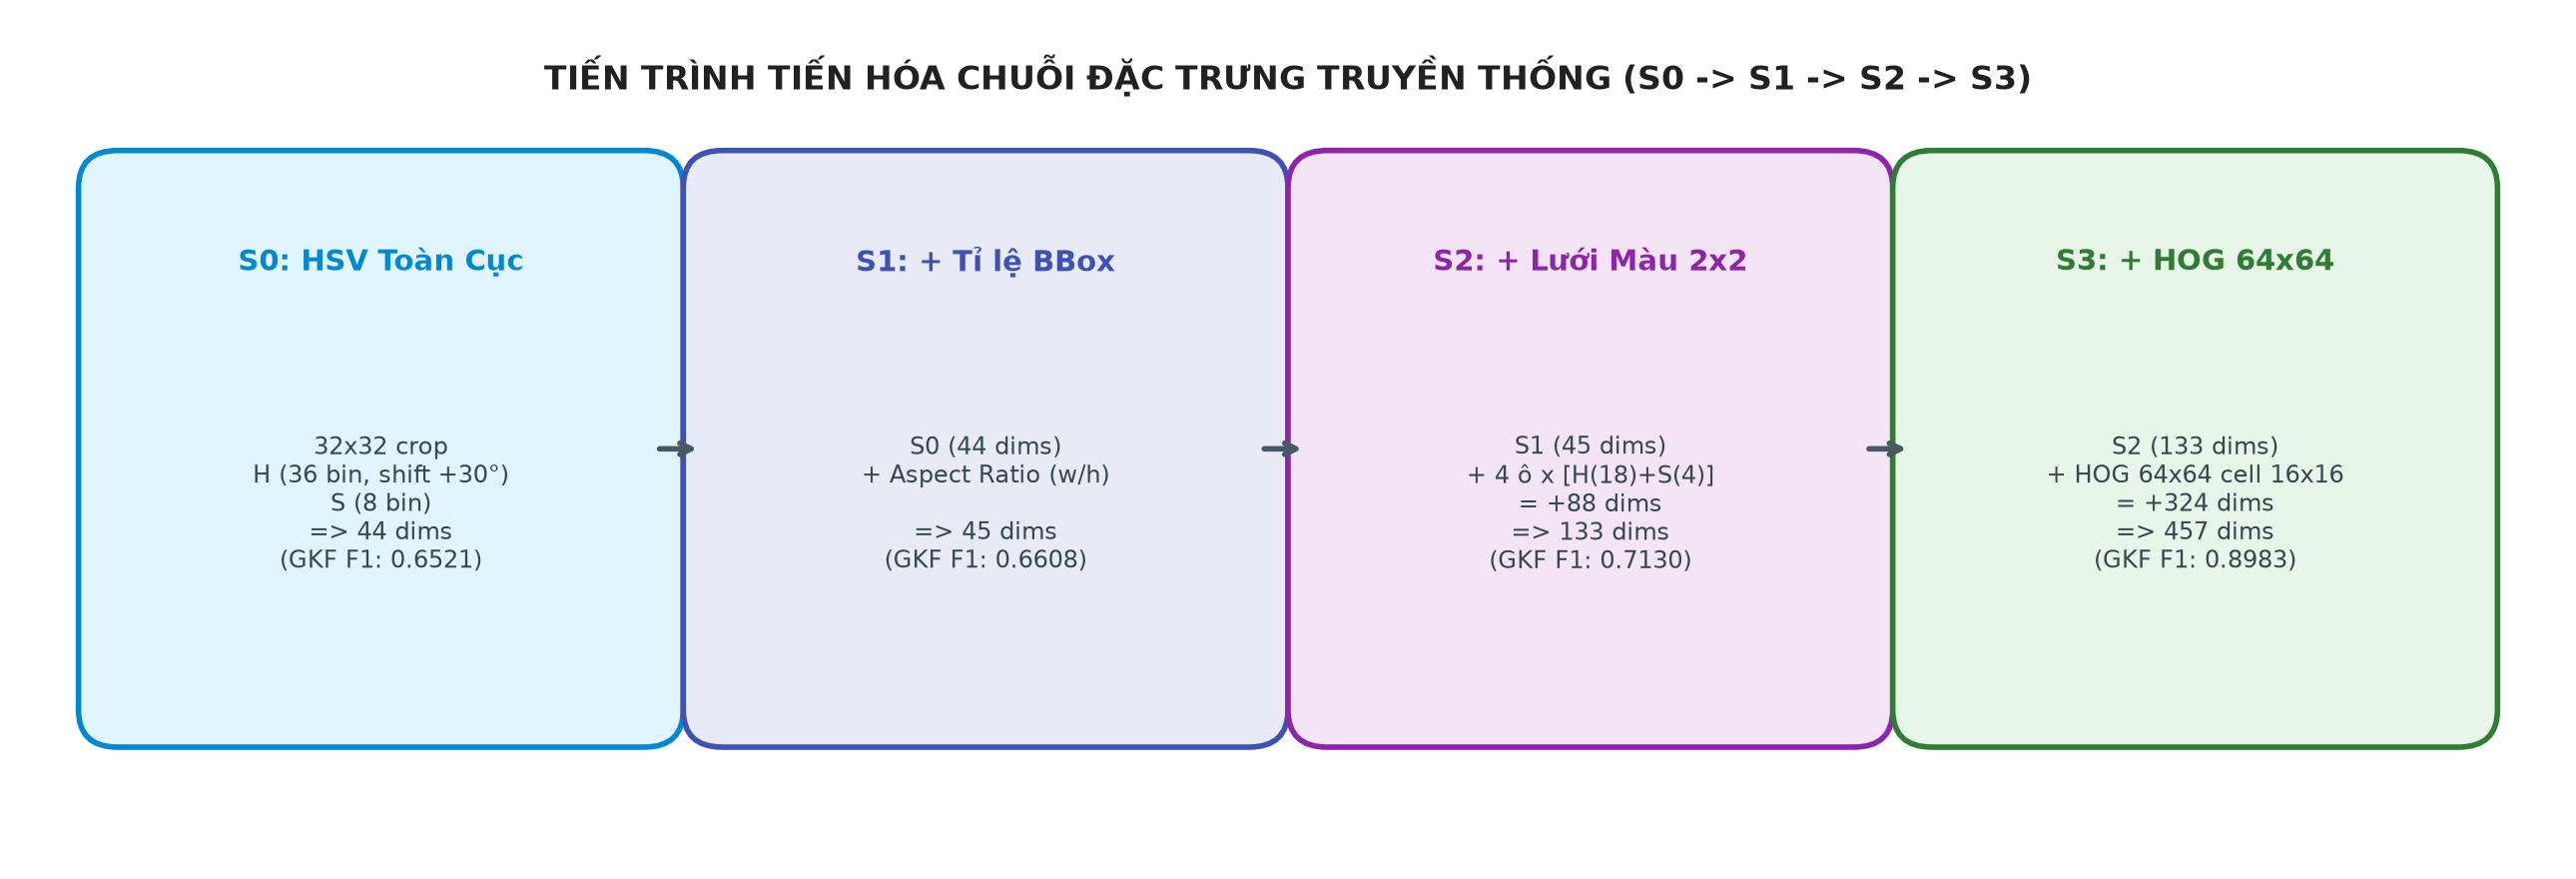

In [5]:
display(Image(filename=str(ASSETS_DIR / "diagrams" / "feature_chain.png"), width=750))
display(Image(filename=str(ASSETS_DIR / "figures" / "chain.png"), width=750))


## 5. Đánh Giá Bộ Phân Loại & Đối Sánh Mô Hình

Chúng tôi so sánh các mô hình: **SVM (RBF kernel)**, **Random Forest**, **XGBoost**, **LightGBM** và **kNN ($k=11$)** qua từng nấc đặc trưng trên tập Test Ground Truth (Level A, 1.821 mẫu).


In [6]:
with open(RESULTS_DIR / "stage2_update_metrics.json", "r", encoding="utf-8") as f:
    metrics = json.load(f)

table_rows = []
for row in metrics["all_results_table"]:
    table_rows.append({
        "Đặc trưng": row["Đặc trưng"],
        "Mô hình": row["Mô hình"],
        "GroupKFold Macro-F1": row["GroupKFold Macro-F1"],
        "Test Acc (%)": round(row["Test Accuracy"] * 100, 2),
        "Test Macro-F1": round(row["Test Macro-F1"], 4),
        "Major 4 F1": round(row["Test Major4 F1"], 4)
    })

df_eval = pd.DataFrame(table_rows)
print("=== BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ MỨC A (1.821 MẪU TEST GT) ===")
display(df_eval[df_eval["Đặc trưng"] == "S3 (+HOG)"])

print("\n✓ Mô hình tối ưu: SVM (RBF kernel) tại nấc S3 đạt Test Macro-F1 = 0.9640, Major 4 F1 = 0.9551, GroupKFold = 0.8983.")
print("ℹ Lưu ý: Giá trị Test Macro-F1 của kNN (k=11) tại S3 đạt 0.9687 ngẫu nhiên trùng khớp về mặt làm tròn với điểm Mức B của SVM.")


=== BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ MỨC A (1.821 MẪU TEST GT) ===
     Đặc trưng        Mô hình GroupKFold Macro-F1  Test Acc (%)  Test Macro-F1  Major 4 F1
20   S3 (+HOG)            SVM   0.8983 ± 0.0746         98.57         0.9640      0.9551
21   S3 (+HOG)            kNN   0.8455 ± 0.1113         98.74         0.9687      0.9609
22   S3 (+HOG)  Random Forest   0.8753 ± 0.0981         98.68         0.9624      0.9530
23   S3 (+HOG)        XGBoost   0.8838 ± 0.0851         98.68         0.9421      0.9554
24   S3 (+HOG)       LightGBM   0.8885 ± 0.0882         98.74         0.9517      0.9544

✓ Mô hình tối ưu: SVM (RBF kernel) tại nấc S3 đạt Test Macro-F1 = 0.9640, Major 4 F1 = 0.9551, GroupKFold = 0.8983.
ℹ Lưu ý: Giá trị Test Macro-F1 của kNN (k=11) tại S3 đạt 0.9687 ngẫu nhiên trùng khớp về mặt làm tròn với điểm Mức B của SVM.


### Ma Trận Nhầm Lẫn (Confusion Matrix): S0 (HSV cơ bản) vs S3 (HSV + Lưới + Hình học + HOG)


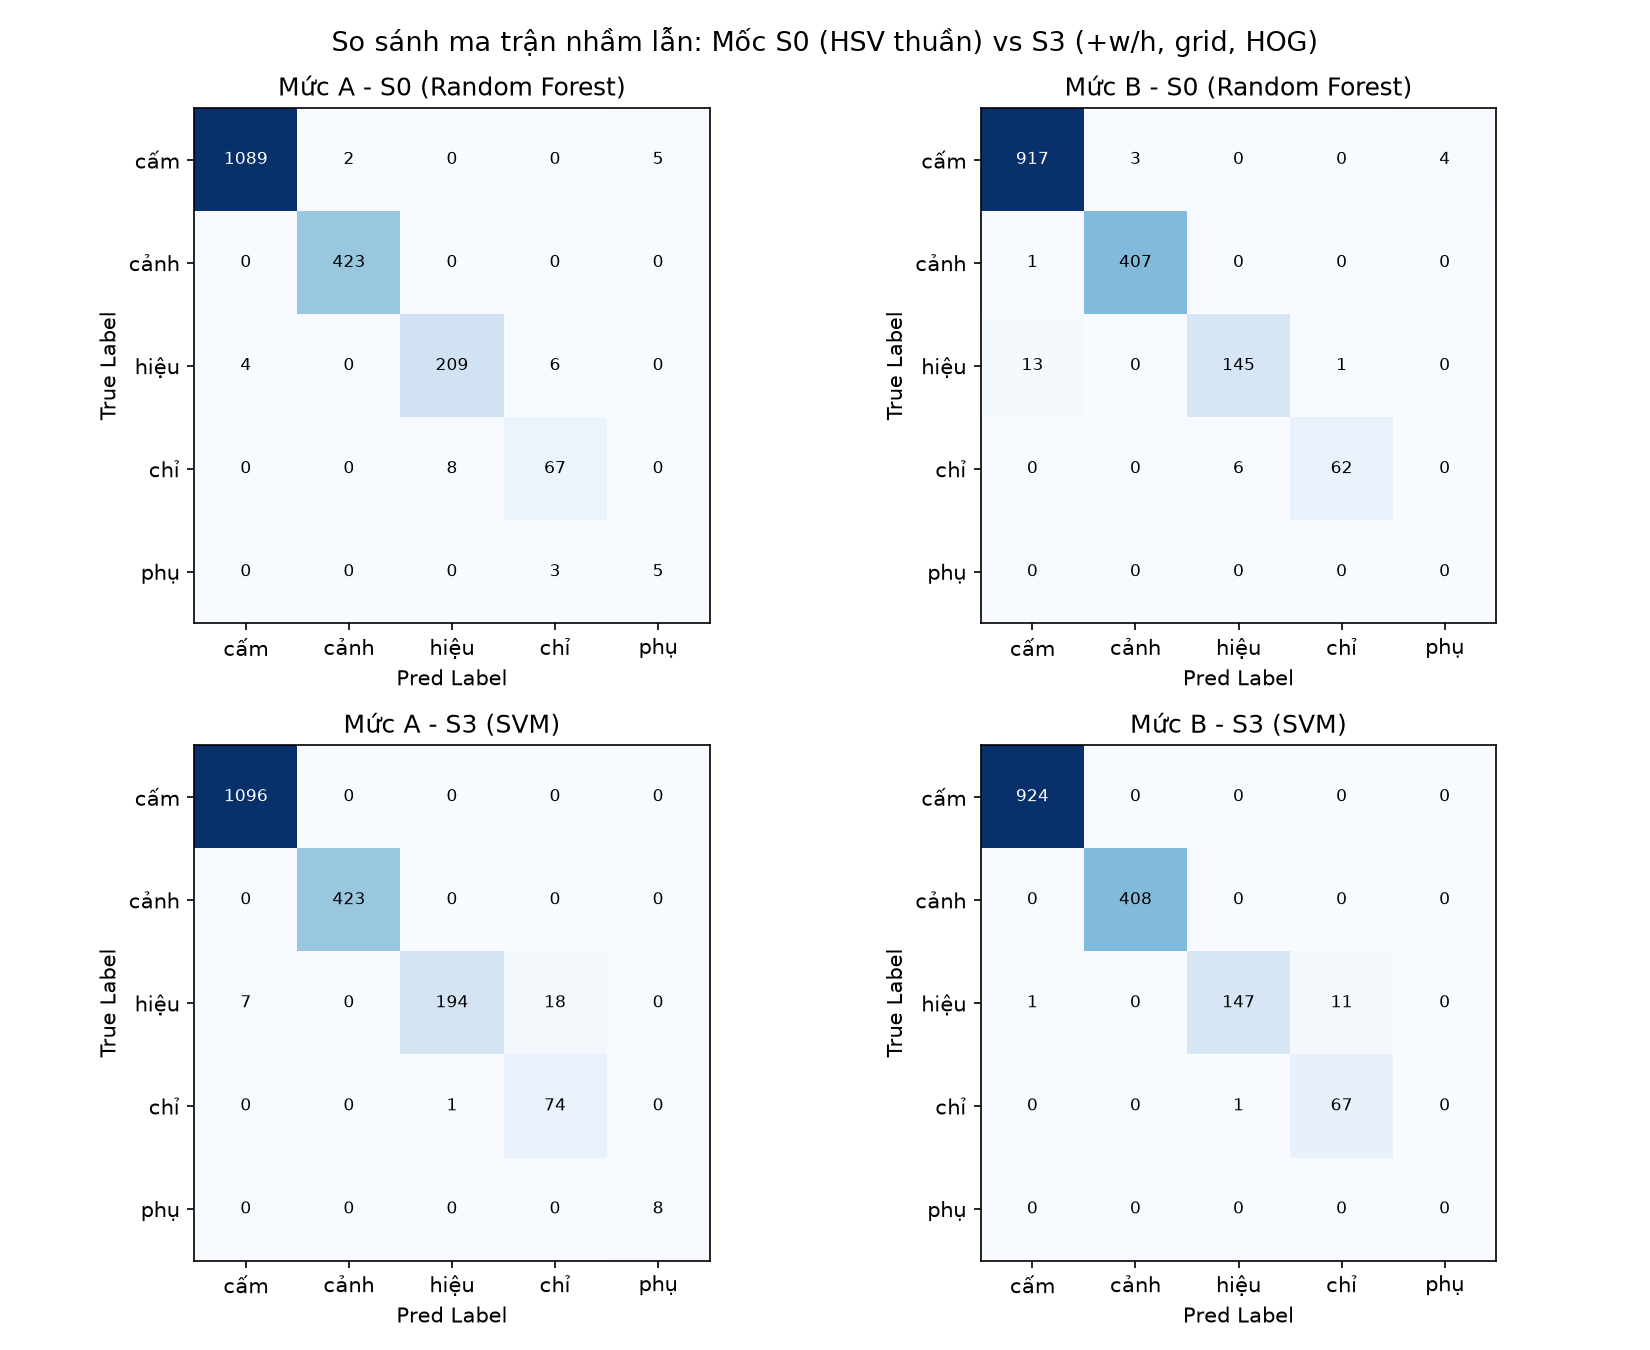

In [7]:
display(Image(filename=str(ASSETS_DIR / "figures" / "cm_compare_S0_vs_S3.png"), width=850))


## 6. Phân Tích Định Tính Qua Contact Sheets


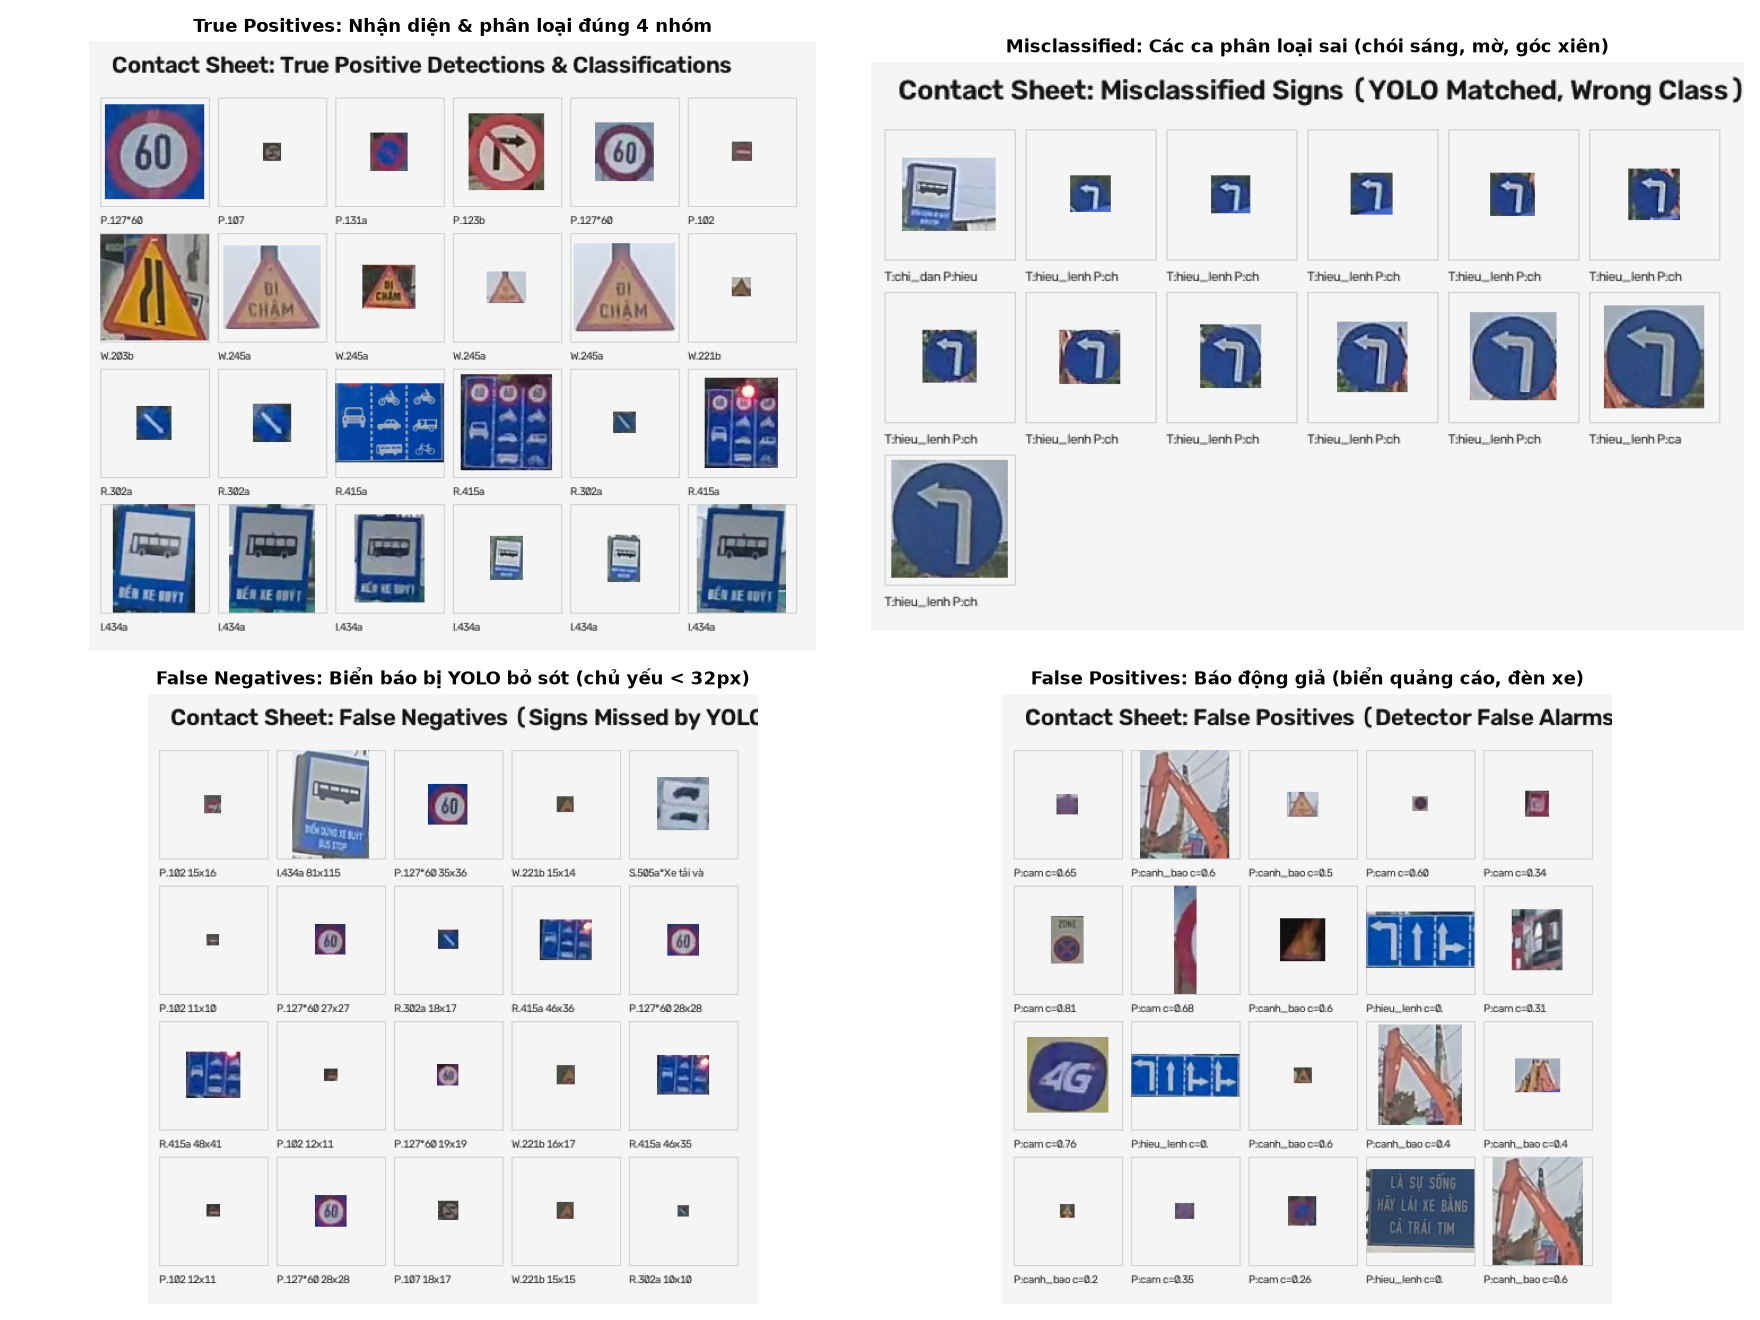

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sheets = [
    ("assets/crops/sheet_tp.png", "True Positives: Nhận diện & phân loại đúng 4 nhóm"),
    ("assets/crops/sheet_wrong.png", "Misclassified: Các ca phân loại sai (chói sáng, mờ, góc xiên)"),
    ("assets/crops/sheet_fn.png", "False Negatives: Biển báo bị YOLO bỏ sót (chủ yếu < 32px)"),
    ("assets/crops/sheet_fp.png", "False Positives: Báo động giả (biển quảng cáo, đèn xe)")
]

for ax, (sheet_rel, title) in zip(axes.ravel(), sheets):
    sp = ROOT_DIR / sheet_rel
    if sp.exists():
        sim = cv2.imread(str(sp))
        ax.imshow(cv2.cvtColor(sim, cv2.COLOR_BGR2RGB))
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 7. Đánh Giá Toàn Diện Hệ Thống Ở 3 Mức (Level A, Level A', Level B)

- **Level A (Ground Truth Bbox):** Đánh giá thuần túy bộ phân loại trên 1.821 biển GT sạch (đã bỏ Camera).
- **Level A' (Detected GT Bbox):** Đánh giá bộ phân loại trên 1.559 biển GT mà YOLO bắt trúng.
- **Level B (End-to-End Pipeline):** Đánh giá trên chính 1.559 crop thực tế do YOLO sinh ra.


In [9]:
levels_data = {
    "Mức đánh giá": ["Level A (GT Bbox)", "Level A' (Matched GT)", "Level B (End-to-End)"],
    "Mô tả đầu vào (đã bỏ Camera)": ["Toàn bộ 1.821 box GT", "1.559 box GT phát hiện trúng", "1.559 box dự đoán từ YOLO"],
    "Accuracy (%)": [98.57, 99.29, 99.17],
    "Macro-F1 (5 nhóm)": [0.9640, 0.9738, 0.9687],
    "Major 4 F1": [0.9551, 0.9634, 0.9609],
    "End-to-End Recall (%)": [100.0, 85.61, 84.90]
}
df_levels = pd.DataFrame(levels_data)
display(df_levels)


Mức đánh giá Mô tả đầu vào (đã bỏ Camera)  Accuracy (%)  Macro-F1 (5 nhóm)  Major 4 F1  End-to-End Recall (%)
0      Level A (GT Bbox)         Toàn bộ 1.821 box GT         98.57             0.9640      0.9551                 100.00
1  Level A' (Matched GT)  1.559 box GT phát hiện trúng         99.29             0.9738      0.9634                  85.61
2    Level B (End-to-End)    1.559 box dự đoán từ YOLO         99.17             0.9687      0.9609                  84.90


## 8. Hướng Dẫn Thực Hiện Dự Đoán Trực Tiếp (Inference Template)


In [10]:
RUN_LIVE_INFERENCE = False  # Đổi thành True sau khi bạn tải weights từ Drive về thư mục models/

if RUN_LIVE_INFERENCE:
    import joblib
    from ultralytics import YOLO
    detector = YOLO("../models/vn_s_best.pt")
    classifier_bundle = joblib.load("../models/stage2_best.joblib")
    print("✓ Đã nạp thành công mô hình. Sẵn sàng thực hiện dự đoán trên ảnh mới!")
else:
    print("ℹ Để chạy inference thực tế:")
    print("  1. Đọc file WEIGHTS.md để lấy link tải vn_s_best.pt và stage2_best.joblib.")
    print("  2. Đặt các file trọng số vào thư mục models/.")
    print("  3. Đặt RUN_LIVE_INFERENCE = True và thực thi lại cell này.")


ℹ Để chạy inference thực tế:
  1. Đọc file WEIGHTS.md để lấy link tải vn_s_best.pt và stage2_best.joblib.
  2. Đặt các file trọng số vào thư mục models/.
  3. Đặt RUN_LIVE_INFERENCE = True và thực thi lại cell này.


## 9. Kết Luận

1. **SVM (RBF kernel) trên S3 (HSV+HOG):** Đạt **Macro-F1 0.9640** (Level A) và **0.9687** (Level B trên 1.559 box YOLO), tốc độ trích xuất và suy luận cực nhanh trên CPU.
2. **Chiến lược Block Split:** Đảm bảo rò rỉ dữ liệu = 0% giữa train và test.
3. **Nút thắt hệ thống:** Tỷ lệ bỏ sót 14.39% của YOLO đối với các biển nhỏ ở xa (< 24px) và biển phụ (0/8 biển phụ bắt được).
